# TP2: Data Preprocessing

**Institute of Technology of Cambodia (ITC)**

**Name: HAK Tontan**

**ID: M0805023**

**Group: M-DAS (M1)**

This notebook contains the solution for both problems:

- **Problem 1** — Warm-up with `Data.csv` (imputation, encoding, splitting, scaling)
- **Problem 2** — Titanic dataset (exploration, missing values, redundancy & leakage, outliers, feature engineering, full pipeline)

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler, MinMaxScaler, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

---
# Problem 1: Warm-up with `Data.csv`

> The file is **tab-separated**, so it must be loaded with `sep="\t"`.

The cell below recreates `Data.csv` only if it is not already in the working folder, so the notebook runs anywhere. If students have the original file, it is used as-is.

In [4]:
import os

if not os.path.exists("Data.csv"):
    data_txt = """Country\tAge\tSalary\tPurchased
France\t44\t72000\tNo
Spain\t27\t48000\tYes
Germany\t30\t54000\tNo
Spain\t38\t61000\tNo
Germany\t40\t\tYes
France\t35\t58000\tYes
Spain\t\t52000\tNo
France\t48\t79000\tYes
Germany\t50\t83000\tNo
France\t37\t67000\tYes
"""
    with open("Data.csv", "w") as f:
        f.write(data_txt)
    print("Data.csv created.")

## Q1. Load and inspect

In [5]:
df = pd.read_csv("Data.csv", sep="\t")

print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
df.head(10)

Shape: (10, 4)

Data types:
Country          str
Age          float64
Salary       float64
Purchased        str
dtype: object


,Country,Age,Salary,Purchased
0,France,44.0,72000.0,No
1,Spain,27.0,48000.0,Yes
2,Germany,30.0,54000.0,No
3,Spain,38.0,61000.0,No
4,Germany,40.0,NaN,Yes
5,France,35.0,58000.0,Yes
6,Spain,NaN,52000.0,No
7,France,48.0,79000.0,Yes
8,Germany,50.0,83000.0,No
9,France,37.0,67000.0,Yes


In [6]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

Numerical  : ['Age', 'Salary']
Categorical: ['Country', 'Purchased']


**Answer.** The dataset has 10 rows and 4 columns.

- **Numerical:** `Age`, `Salary` (stored as `float64` because they contain `NaN`; a missing value forces a float type).
- **Categorical:** `Country` (nominal, 3 categories) and `Purchased` (binary target: Yes/No).

## Q2. Find missing values

In [7]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nRows that contain at least one missing value:")
df[df.isnull().any(axis=1)]

Missing values per column:
Country      0
Age          1
Salary       1
Purchased    0
dtype: int64

Rows that contain at least one missing value:


,Country,Age,Salary,Purchased
4,Germany,40.0,NaN,Yes
6,Spain,NaN,52000.0,No


In [8]:
for col in df.columns:
    rows = df.index[df[col].isnull()].tolist()
    if rows:
        print(f"{col:8s}: {len(rows)} missing, at row index {rows}")

Age     : 1 missing, at row index [6]
Salary  : 1 missing, at row index [4]


**Answer.** Two values are missing: one `Salary` (row index 4, Germany, age 40) and one `Age` (row index 6, Spain, salary 52000). `Country` and `Purchased` are complete.

## Q3. Split features and target

In [9]:
X = df[["Country", "Age", "Salary"]]
y = df["Purchased"]

print("X shape:", X.shape)
print("y shape:", y.shape)
X

X shape: (10, 3)
y shape: (10,)


,Country,Age,Salary
0,France,44.0,72000.0
1,Spain,27.0,48000.0
2,Germany,30.0,54000.0
3,Spain,38.0,61000.0
4,Germany,40.0,NaN
5,France,35.0,58000.0
6,Spain,NaN,52000.0
7,France,48.0,79000.0
8,Germany,50.0,83000.0
9,France,37.0,67000.0


## Q4. Impute missing values (mean vs median)

In [10]:
X_mean = X.copy()
imputer_mean = SimpleImputer(strategy="mean")
X_mean[["Age", "Salary"]] = imputer_mean.fit_transform(X[["Age", "Salary"]])

print("Values learned by the mean imputer (Age, Salary):", imputer_mean.statistics_)
X_mean

Values learned by the mean imputer (Age, Salary): [3.87777778e+01 6.37777778e+04]


,Country,Age,Salary
0,France,44.000000,72000.000000
1,Spain,27.000000,48000.000000
2,Germany,30.000000,54000.000000
3,Spain,38.000000,61000.000000
4,Germany,40.000000,63777.777778
5,France,35.000000,58000.000000
6,Spain,38.777778,52000.000000
7,France,48.000000,79000.000000
8,Germany,50.000000,83000.000000
9,France,37.000000,67000.000000


In [11]:
X_median = X.copy()
imputer_median = SimpleImputer(strategy="median")
X_median[["Age", "Salary"]] = imputer_median.fit_transform(X[["Age", "Salary"]])

comparison = pd.DataFrame({
    "mean":   imputer_mean.statistics_,
    "median": imputer_median.statistics_,
}, index=["Age", "Salary"])
comparison

,mean,median
Age,38.777778,38.0
Salary,63777.777778,61000.0


**Answer.**

| | Mean | Median |
|---|---|---|
| Age (row 6) | 38.78 | 38 |
| Salary (row 4) | 63 777.78 | 61 000 |

Here the two strategies give close values because this small dataset has no extreme values.

**When is the median better?** The mean is pulled toward extreme values; the median is not. The median is the better choice when the distribution is **skewed** or contains **outliers**. Salary is the classic example: one executive earning 1 000 000 would raise the mean salary a lot, and every missing salary would be filled with an unrealistically high value. The median stays at the "typical" employee. The mean is fine for roughly symmetric distributions without outliers.

## Q5. Encode `Country` with one-hot encoding

In [12]:
ct = ColumnTransformer(
    transformers=[("onehot", OneHotEncoder(sparse_output=False), ["Country"])],
    remainder="passthrough",
)
X_encoded = ct.fit_transform(X_mean)

feature_names = ct.get_feature_names_out()
X_encoded_df = pd.DataFrame(X_encoded, columns=feature_names)
X_encoded_df

,onehot__Country_France,onehot__Country_Germany,onehot__Country_Spain,remainder__Age,remainder__Salary
0,1.0,0.0,0.0,44.000000,72000.000000
1,0.0,0.0,1.0,27.000000,48000.000000
2,0.0,1.0,0.0,30.000000,54000.000000
3,0.0,0.0,1.0,38.000000,61000.000000
4,0.0,1.0,0.0,40.000000,63777.777778
5,1.0,0.0,0.0,35.000000,58000.000000
6,0.0,0.0,1.0,38.777778,52000.000000
7,1.0,0.0,0.0,48.000000,79000.000000
8,0.0,1.0,0.0,50.000000,83000.000000
9,1.0,0.0,0.0,37.000000,67000.000000


**Why France = 0, Spain = 1, Germany = 2 is a bad idea.**
Label encoding gives the categories an **artificial order and distance** that do not exist. A model would read Germany (2) > Spain (1) > France (0), and conclude that "Spain is halfway between France and Germany", or that Germany = 2 × Spain. Linear models, KNN, SVM, and neural networks all use these numbers in arithmetic, so the meaningless order directly changes predictions.

One-hot encoding creates one binary column per country. All countries are at the same distance from each other, and no order is implied. This is the right choice for **nominal** variables.

## Q6. Encode the target

In [13]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Classes:", le.classes_, "->", le.transform(le.classes_))
print("y encoded:", y_encoded)

Classes: ['No' 'Yes'] -> [0 1]
y encoded: [0 1 0 0 1 1 0 1 0 1]


`LabelEncoder` sorts the classes alphabetically, so **No → 0** and **Yes → 1**. Label encoding is acceptable for the **target** because the model treats it as class labels, not as a numeric feature.

## Q7. Split the data (80/20, `random_state=1`)

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded_df, y_encoded, test_size=0.2, random_state=1
)
print("X_train:", X_train.shape, " X_test:", X_test.shape)
X_train

X_train: (8, 5)  X_test: (2, 5)


,onehot__Country_France,onehot__Country_Germany,onehot__Country_Spain,remainder__Age,remainder__Salary
6,0.0,0.0,1.0,38.777778,52000.000000
4,0.0,1.0,0.0,40.000000,63777.777778
0,1.0,0.0,0.0,44.000000,72000.000000
3,0.0,0.0,1.0,38.000000,61000.000000
1,0.0,0.0,1.0,27.000000,48000.000000
7,1.0,0.0,0.0,48.000000,79000.000000
8,0.0,1.0,0.0,50.000000,83000.000000
5,1.0,0.0,0.0,35.000000,58000.000000


In [ ]:
X_test

**Why split before scaling?** The test set must simulate **new, unseen data**. If the scaler is fitted on the full dataset, its mean and standard deviation already contain information from the test rows. The model is then evaluated on data that indirectly influenced the training, which gives an optimistic and dishonest score. This is called **data leakage**.

The correct order is: **split → fit the scaler on the training set → apply (transform) it to both sets**.

> Note: strictly speaking, the same rule applies to imputation. In Q4 the imputer was fitted on all 10 rows, so the test rows influenced the filled mean. Problem 2 (Q-Pipeline) shows the correct way, where imputation is fitted on the training set only.

## Q8. Scale `Age` and `Salary` with `StandardScaler` (fit on training set only)

In [15]:
num_features = ["remainder__Age", "remainder__Salary"]

X_train_std = X_train.copy()
X_test_std = X_test.copy()

sc = StandardScaler()
X_train_std[num_features] = sc.fit_transform(X_train[num_features])   # fit + transform on train
X_test_std[num_features]  = sc.transform(X_test[num_features])        # transform only on test

print("Learned mean :", sc.mean_)
print("Learned std  :", sc.scale_)
print("\nTraining set:")
display(X_train_std.round(3))
print("Test set:")
display(X_test_std.round(3))

Learned mean : [4.00972222e+01 6.45972222e+04]
Learned std  : [6.88674642e+00 1.16843698e+04]

Training set:


,onehot__Country_France,onehot__Country_Germany,onehot__Country_Spain,remainder__Age,remainder__Salary
6,0.0,0.0,1.0,-0.192,-1.078
4,0.0,1.0,0.0,-0.014,-0.070
0,1.0,0.0,0.0,0.567,0.634
3,0.0,0.0,1.0,-0.305,-0.308
1,0.0,0.0,1.0,-1.902,-1.420
7,1.0,0.0,0.0,1.148,1.233
8,0.0,1.0,0.0,1.438,1.575
5,1.0,0.0,0.0,-0.740,-0.565


Test set:


,onehot__Country_France,onehot__Country_Germany,onehot__Country_Spain,remainder__Age,remainder__Salary
2,0.0,1.0,0.0,-1.466,-0.907
9,1.0,0.0,0.0,-0.450,0.206


After standardization, the training columns have mean ≈ 0 and standard deviation = 1. The test values are expressed in the same units (computed with the **training** mean and std), so they are not exactly centered at 0. This is expected.

**Should the one-hot columns also be scaled?** In general, **no**:

- They are already on a small 0/1 scale, comparable to standardized values.
- Scaling them destroys their interpretation ("1 = this country") and gives values like −0.65 / 1.53 that mean nothing to a human.
- Tree-based models do not need scaling at all.

There are exceptions: for distance-based models (KNN, K-Means) or models with regularization, some practitioners scale everything so all features have the same weight. It rarely changes results much. The common practice taught in this course is to scale only the real numerical features.

## Q9. Compare with `MinMaxScaler`

In [16]:
X_train_mm = X_train.copy()
X_test_mm = X_test.copy()

mm = MinMaxScaler()
X_train_mm[num_features] = mm.fit_transform(X_train[num_features])
X_test_mm[num_features]  = mm.transform(X_test[num_features])

compare = pd.DataFrame({
    "Age_raw":       X_train["remainder__Age"].values,
    "Age_standard":  X_train_std["remainder__Age"].values,
    "Age_minmax":    X_train_mm["remainder__Age"].values,
    "Salary_raw":    X_train["remainder__Salary"].values,
    "Salary_standard": X_train_std["remainder__Salary"].values,
    "Salary_minmax": X_train_mm["remainder__Salary"].values,
}, index=X_train.index).round(3)
print("Training set comparison:")
display(compare)

print("Test set with MinMaxScaler:")
display(X_test_mm.round(3))

Training set comparison:


,Age_raw,Age_standard,Age_minmax,Salary_raw,Salary_standard,Salary_minmax
6,38.778,-0.192,0.512,52000.000,-1.078,0.114
4,40.000,-0.014,0.565,63777.778,-0.070,0.451
0,44.000,0.567,0.739,72000.000,0.634,0.686
3,38.000,-0.305,0.478,61000.000,-0.308,0.371
1,27.000,-1.902,0.000,48000.000,-1.420,0.000
7,48.000,1.148,0.913,79000.000,1.233,0.886
8,50.000,1.438,1.000,83000.000,1.575,1.000
5,35.000,-0.740,0.348,58000.000,-0.565,0.286


Test set with MinMaxScaler:


,onehot__Country_France,onehot__Country_Germany,onehot__Country_Spain,remainder__Age,remainder__Salary
2,0.0,1.0,0.0,0.130,0.171
9,1.0,0.0,0.0,0.435,0.543


**How the values differ.**

| | StandardScaler | MinMaxScaler |
|---|---|---|
| Formula | $z = \dfrac{x - \mu}{\sigma}$ | $x' = \dfrac{x - x_{min}}{x_{max} - x_{min}}$ |
| Training range | unbounded, centered at 0 (mostly between −2 and 2) | exactly [0, 1] |
| Negative values | yes | no (on training data) |
| Sensitivity to outliers | moderate | high: one extreme value squeezes all the others near 0 |

The **order** of the values is identical; only the scale changes. Test values can fall slightly **outside [0, 1]** with MinMaxScaler if they are smaller or larger than the training min/max.

Rule of thumb: use **StandardScaler** by default (linear/logistic regression, SVM, PCA); use **MinMaxScaler** when a bounded range is required (e.g., neural network inputs, image pixels) and the data has no strong outliers.

---
# Problem 2: Titanic dataset

In [25]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df_raw = pd.read_csv(url)
titanic = df_raw.copy()
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


# **Problem 2:** Titanic dataset

## 1 Exploration:
### 1a.Shape, info() and Decribe()


In [26]:
print("Shape:", titanic.shape)
print("\n--- Info ---")
titanic.info()

print("\n--- Numerical Summary ---")
display(titanic.describe())

print("\n--- Categorical Summary ---")
display(titanic.describe(include=["object", "category", "bool"]))

n_passengers = len(titanic)
survival_rate = titanic["survived"].mean() * 100
print(f"\nTotal passengers: {n_passengers}")
print(f"Survival rate   : {survival_rate:.2f}% ({titanic['survived'].sum()} survived)")

Shape: (891, 15)

--- Info ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB

--- Numerical Summary ---


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



--- Categorical Summary ---


C:\Users\Tontan HAK\AppData\Local\Temp\ipykernel_11004\2745645649.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(titanic.describe(include=["object", "category", "bool"]))


,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537



Total passengers: 891
Survival rate   : 38.38% (342 survived)


In [27]:
print("Shape:", titanic.shape)
titanic.info()

Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [28]:
titanic.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [29]:
titanic.describe(exclude="number")

,sex,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891,889,891,891,891,203,889,891,891
unique,2,3,3,3,2,7,3,2,2
top,male,S,Third,man,True,C,Southampton,no,True
freq,577,644,491,537,537,59,644,549,537


In [30]:
n_passengers = len(titanic)
survival_rate = titanic["survived"].mean() * 100
print(f"\nTotal passengers: {n_passengers}")
print(f"Survival rate   : {survival_rate:.2f}% ({titanic['survived'].sum()} survived)")
print(f"Died      : {(titanic['survived'] == 0).sum()} ({100 - survival_rate:.2f}%)")


Total passengers: 891
Survival rate   : 38.38% (342 survived)
Died      : 549 (61.62%)


### 1.B.Missing Values table

In [31]:
missing_count = titanic.isnull().sum()
missing_pct = (missing_count / len(titanic)) * 100

missing_df = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing (%)": missing_pct.round(2)
}).sort_values(by="Missing Count", ascending=False)

display(missing_df[missing_df["Missing Count"] > 0])

,Missing Count,Missing (%)
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


## 2.Handling missing values
### 2a.Decisions & Imputations 
- deck
- age
- embarked

In [32]:
# i. deck -> create binary indicator has_deck and drop deck
titanic["has_deck"] = titanic["deck"].notnull().astype(int)
titanic.drop(columns=["deck"], inplace=True)

# ii. age -> compare overall median vs grouped median (by pclass and sex)
age_overall_median = titanic["age"].fillna(titanic["age"].median())
age_grouped_median = titanic["age"].fillna(
    titanic.groupby(["pclass", "sex"])["age"].transform("median")
)

print("Group medians (pclass, sex):")
display(titanic.groupby(["pclass", "sex"])["age"].median())

age_comp = pd.DataFrame({
    "Original (non-null)": titanic["age"].dropna(),
    "Overall Median Imputed": age_overall_median,
    "Grouped Median Imputed": age_grouped_median
}).describe().round(2)
display(age_comp)

# Apply the grouped median imputation
titanic["age"] = age_grouped_median

# iii. embarked -> impute with mode
embarked_mode = titanic["embarked"].mode()[0]
titanic["embarked"] = titanic["embarked"].fillna(embarked_mode)
print(f"Imputed embarked with mode: '{embarked_mode}'")

Group medians (pclass, sex):


C:\Users\Tontan HAK\AppData\Local\Temp\ipykernel_11004\1135266778.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  titanic.drop(columns=["deck"], inplace=True)


pclass  sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: age, dtype: float64

,Original (non-null),Overall Median Imputed,Grouped Median Imputed
count,714.00,891.00,891.00
mean,29.70,29.36,29.11
std,14.53,13.02,13.30
min,0.42,0.42,0.42
25%,20.12,22.00,21.50
50%,28.00,28.00,26.00
75%,38.00,35.00,36.00
max,80.00,80.00,80.00


Imputed embarked with mode: 'S'


## 2b. Survival rate before vs. after dropping missing

In [33]:
sr_before = df_raw["survived"].mean() * 100
sr_after_drop = df_raw.dropna(subset=["age"])["survived"].mean() * 100

print(f"Survival rate BEFORE dropping missing age : {sr_before:.2f}% (n={len(df_raw)})")
print(f"Survival rate AFTER dropping missing age  : {sr_after_drop:.2f}% (n={df_raw['age'].notnull().sum()})")

Survival rate BEFORE dropping missing age : 38.38% (n=891)
Survival rate AFTER dropping missing age  : 40.62% (n=714)


# 3. Redundancy and leakage
## 3a. Identify and drop redundant columns

In [34]:
# Verify exact 1-to-1 or overlapping relationships
print("survived vs alive:")
display(pd.crosstab(titanic["survived"], titanic["alive"]))

print("\npclass vs class:")
display(pd.crosstab(titanic["pclass"], titanic["class"]))

print("\nembarked vs embark_town:")
display(pd.crosstab(titanic["embarked"], titanic["embark_town"]))

print("\nsex vs who vs adult_male:")
display(pd.crosstab([titanic["sex"], titanic["adult_male"]], titanic["who"]))

# Drop redundant / leaky columns
redundant_cols = ["alive", "class", "embark_town", "who", "adult_male"]
titanic.drop(columns=redundant_cols, inplace=True)
print("Remaining columns:", titanic.columns.tolist())

survived vs alive:


alive,no,yes
survived,,
0,549,0
1,0,342



pclass vs class:


class,First,Second,Third
pclass,,,
1,216,0,0
2,0,184,0
3,0,0,491



embarked vs embark_town:


embark_town,Cherbourg,Queenstown,Southampton
embarked,,,
C,168,0,0
Q,0,77,0
S,0,0,644



sex vs who vs adult_male:


who                child  man  woman
sex    adult_male                   
female False          43    0    271
male   False          40    0      0
       True            0  537      0

Remaining columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone', 'has_deck']


C:\Users\Tontan HAK\AppData\Local\Temp\ipykernel_11004\1491644615.py:16: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  titanic.drop(columns=redundant_cols, inplace=True)


## 3b. Target leakage (alive)

- **Target leakage occurs when a feature in the training data contains information about the target variable that would not be available at prediction time.**
- **Keeping alive when predicting survived is direct target leakage because alive is just the text version of survived. A model trained with alive will achieve 100% accuracy during training/testing by simply copying alive, but it will completely fail in production when predicting survival for new passengers whose outcome is unknown.**

# 4. Duplicates and outliers
## 4a. Check duplicated rows

In [35]:
dup_count = titanic.duplicated().sum()
print(f"Number of duplicated rows: {dup_count}")
display(titanic[titanic.duplicated(keep=False)].sort_values(by=["pclass", "age", "fare"]).head(10))

Number of duplicated rows: 113


,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone,has_deck
369,1,1,female,24.0,0,0,69.3000,C,True,1
641,1,1,female,24.0,0,0,69.3000,C,True,1
263,0,1,male,40.0,0,0,0.0000,S,True,1
815,0,1,male,40.0,0,0,0.0000,S,True,1
30,0,1,male,40.0,0,0,27.7208,C,True,0
64,0,1,male,40.0,0,0,27.7208,C,True,0
295,0,1,male,40.0,0,0,27.7208,C,True,0
144,0,2,male,18.0,0,0,11.5000,S,True,0
757,0,2,male,18.0,0,0,11.5000,S,True,0
658,0,2,male,23.0,0,0,13.0000,S,True,0


## 4b. Boxplot of fare and IQR outlier detection


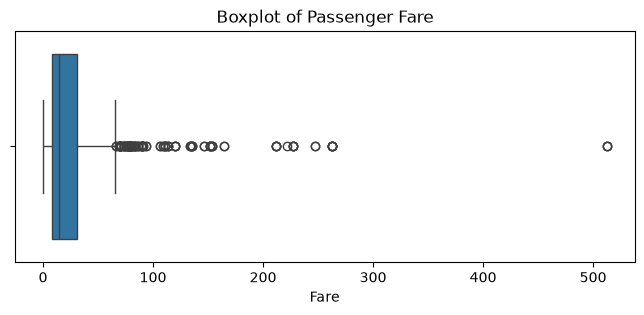

Q1 = 7.91, Q3 = 31.00, IQR = 23.09
Bounds: [-26.72, 65.63]
Number of IQR outliers in fare: 116 (13.02%)


In [36]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=titanic["fare"])
plt.title("Boxplot of Passenger Fare")
plt.xlabel("Fare")
plt.show()

Q1 = titanic["fare"].quantile(0.25)
Q3 = titanic["fare"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = titanic[(titanic["fare"] < lower_bound) | (titanic["fare"] > upper_bound)]
print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print(f"Bounds: [{lower_bound:.2f}, {upper_bound:.2f}]")
print(f"Number of IQR outliers in fare: {len(outliers)} ({len(outliers)/len(titanic)*100:.2f}%)")

## 4c. Passengers with <fare == 0>

In [37]:
zero_fare = titanic[titanic["fare"] == 0]
print(f"Number of passengers with fare == 0: {len(zero_fare)}")
display(zero_fare)

Number of passengers with fare == 0: 15


,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone,has_deck
179,0,3,male,36.0,0,0,0.0,S,True,0
263,0,1,male,40.0,0,0,0.0,S,True,1
271,1,3,male,25.0,0,0,0.0,S,True,0
277,0,2,male,30.0,0,0,0.0,S,True,0
302,0,3,male,19.0,0,0,0.0,S,True,0
413,0,2,male,30.0,0,0,0.0,S,True,0
466,0,2,male,30.0,0,0,0.0,S,True,0
481,0,2,male,30.0,0,0,0.0,S,True,0
597,0,3,male,49.0,0,0,0.0,S,True,0
633,0,1,male,40.0,0,0,0.0,S,True,0


## 4d. Log transformation (np.log1p) and skewness


Skewness BEFORE log1p: 4.7873
Skewness AFTER  log1p: 0.3949


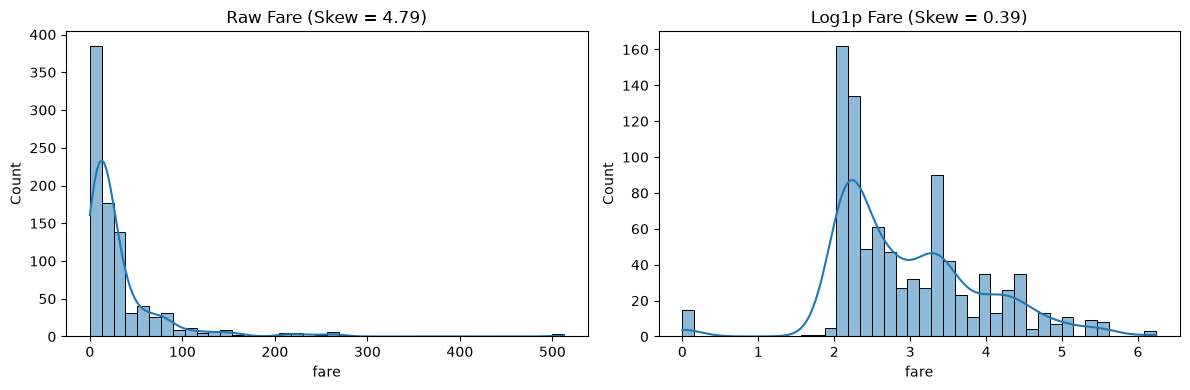

In [38]:
fare_log = np.log1p(titanic["fare"])

print(f"Skewness BEFORE log1p: {titanic['fare'].skew():.4f}")
print(f"Skewness AFTER  log1p: {fare_log.skew():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(titanic["fare"], bins=40, kde=True, ax=axes[0])
axes[0].set_title(f"Raw Fare (Skew = {titanic['fare'].skew():.2f})")

sns.histplot(fare_log, bins=40, kde=True, ax=axes[1])
axes[1].set_title(f"Log1p Fare (Skew = {fare_log.skew():.2f})")
plt.tight_layout()
plt.show()

# 5. Feature engineering
## 5a. family_size vs alone

In [39]:
titanic["family_size"] = titanic["sibsp"] + titanic["parch"] + 1

# Check consistency between family_size == 1 and alone
consistency_check = pd.crosstab(titanic["family_size"] == 1, titanic["alone"])
display(consistency_check)

is_consistent = ((titanic["family_size"] == 1) == titanic["alone"]).all()
print("Are family_size and alone 100% consistent?", is_consistent)

alone,False,True
family_size,,
False,354,0
True,0,537


Are family_size and alone 100% consistent? True


## 5b. Binning age and fare, and comparing survival rates

In [40]:
# Age bins: Child (0-12), Teen (12-18), Adult (18-60), Senior (60+)
age_bins = [0, 12, 18, 60, 100]
age_labels = ["Child", "Teen", "Adult", "Senior"]
titanic["age_group"] = pd.cut(titanic["age"], bins=age_bins, labels=age_labels)

# Fare quartiles
titanic["fare_quartile"] = pd.qcut(titanic["fare"], q=4, labels=["Q1 (Lowest)", "Q2", "Q3", "Q4 (Highest)"])

print("--- Survival Rate by Age Group ---")
display(titanic.groupby("age_group", observed=False)["survived"].agg(["count", "mean"]).rename(columns={"mean": "survival_rate"}))

print("\n--- Survival Rate by Fare Quartile ---")
display(titanic.groupby("fare_quartile", observed=False)["survived"].agg(["count", "mean"]).rename(columns={"mean": "survival_rate"}))

--- Survival Rate by Age Group ---


,count,survival_rate
age_group,,
Child,69,0.579710
Teen,70,0.428571
Adult,730,0.365753
Senior,22,0.227273



--- Survival Rate by Fare Quartile ---


,count,survival_rate
fare_quartile,,
Q1 (Lowest),223,0.197309
Q2,224,0.303571
Q3,222,0.454955
Q4 (Highest),222,0.581081


# 6. Encoding, splitting, and pipeline
## 6a. Encoding strategy discussion

- sex: Binary encoding (male $\rightarrow 0$, female $\rightarrow 1$) via OrdinalEncoder or OneHotEncoder(drop="if_binary") is ideal since there are only two categories.
- embarked: Nominal categorical variable with no natural ordering (C, Q, S), so One-Hot Encoding is required.
- pclass: Can be justified either way depending on the model, though keeping it as ordinal (1, 2, 3) or one-hot encoding have clear trade-offs:
    - Ordinal (1, 2, 3): pclass has a genuine monotonic order (1st > 2nd > 3rd class in socioeconomic status and survival rate). Treating it as numeric preserves this natural ranking in a single column.
    - One-Hot Encoding: If using a linear model and the jump in survival probability from 1st to 2nd class is not equal to the jump from 2nd to 3rd class, one-hot encoding allows the model to learn separate weights for each class without assuming equal spacing. (In the pipeline below, we pass pclass through as an ordinal numeric feature, or you can include it in OneHotEncoder).

## 6b. Stratified 80/20 train-test split

In [41]:
# Start cleanly from raw data to prevent any leakage into the pipeline
df_pipe = df_raw.copy()

# Create has_deck and family_size (row-wise deterministic features with no leakage)
df_pipe["has_deck"] = df_pipe["deck"].notnull().astype(int)
df_pipe["family_size"] = df_pipe["sibsp"] + df_pipe["parch"] + 1

feature_cols = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "has_deck", "family_size"]
X = df_pipe[feature_cols]
y = df_pipe["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train survival rate: {y_train.mean():.4f}")
print(f"Test  survival rate: {y_test.mean():.4f}")

Train survival rate: 0.3834
Test  survival rate: 0.3855


## 6c. Full Pipeline with ColumnTransformer

In [43]:
# Define feature groups
num_skewed = ["fare"]
num_regular = ["age", "sibsp", "parch", "family_size"]
ordinal_cols = ["pclass", "has_deck"]
binary_cols = ["sex"]
nominal_cols = ["embarked"]

# Sub-pipelines
skewed_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_nominal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

cat_binary_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("binary", OneHotEncoder(drop="if_binary", sparse_output=False))
])

# Combine into ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("skewed_num", skewed_pipeline, num_skewed),
        ("num", num_pipeline, num_regular),
        ("nominal", cat_nominal_pipeline, nominal_cols),
        ("binary", cat_binary_pipeline, binary_cols),
        ("ordinal", "passthrough", ordinal_cols)
    ]
)

# Full preprocessing pipeline
full_pipeline = Pipeline([
    ("preprocessing", preprocessor)
])

# Fit on training set ONLY, then transform both
X_train_processed = full_pipeline.fit_transform(X_train)
X_test_processed = full_pipeline.transform(X_test)

print("X_train_processed shape:", X_train_processed.shape)
print("X_test_processed  shape:", X_test_processed.shape)

# Inspect transformed feature names
processed_cols = full_pipeline.named_steps["preprocessing"].get_feature_names_out()
display(pd.DataFrame(X_train_processed, columns=processed_cols).head())

X_train_processed shape: (712, 11)
X_test_processed  shape: (179, 11)


,skewed_num__fare,num__age,num__sibsp,num__parch,num__family_size,nominal__embarked_C,nominal__embarked_Q,nominal__embarked_S,binary__sex_male,ordinal__pclass,ordinal__has_deck
0,1.124592,-0.081135,-0.465084,-0.466183,-0.556339,0.0,0.0,1.0,1.0,3.0,0.0
1,-3.014278,-0.081135,-0.465084,-0.466183,-0.556339,0.0,0.0,1.0,1.0,2.0,0.0
2,2.508198,-0.081135,-0.465084,-0.466183,-0.556339,0.0,0.0,1.0,1.0,1.0,1.0
3,-0.627019,-0.887827,-0.465084,0.727782,0.073412,0.0,0.0,1.0,0.0,3.0,0.0
4,0.361872,0.110934,0.478335,0.727782,0.703162,0.0,0.0,1.0,0.0,2.0,0.0
